# Autoencoders con Keras

https://blog.keras.io/building-autoencoders-in-keras.html

In [1]:
from keras.layers import Input, Dense
from keras.models import Model


In [ ]:
# PCA casi-exacto
# dimension de dominio intermedio
encoding_dim = 32

input_img = Input(shape=(784,))
# ENCODER
encoded = Dense(encoding_dim, activation='linear')(input_img)
# DECODER
decoded = Dense(784, activation='linear')(encoded)

# AUTOENCODER
pca = Model(input_img, decoded)

In [2]:
# dimension de dominio intermedio
encoding_dim = 32

input_img = Input(shape=(784,))
# ENCODER
encoded = Dense(encoding_dim, activation='relu')(input_img)
# DECODER
decoded = Dense(784, activation='sigmoid')(encoded)

# AUTOENCODER
autoencoder = Model(input_img, decoded)

In [3]:
# Modelo para el encoder
encoder = Model(input_img, encoded)

In [4]:
# placeholder
encoded_input = Input(shape=(encoding_dim,))
# capa del decoder
decoder_layer = autoencoder.layers[-1]
# Modelo del decoder
decoder = Model(encoded_input, decoder_layer(encoded_input))

In [5]:
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

In [6]:
from keras.datasets import mnist
import numpy as np
(x_train, _), (x_test, _) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
# DATOS
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))
print(x_train.shape)
print(x_test.shape)

(60000, 784)
(10000, 784)


In [8]:
# ENTRENAMIENTO
autoencoder.fit(x_train, x_train,
                epochs=50,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test, x_test))

Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3812 - val_loss: 0.1888
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1791 - val_loss: 0.1521
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1481 - val_loss: 0.1332
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1314 - val_loss: 0.1210
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1202 - val_loss: 0.1127
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1126 - val_loss: 0.1072
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1075 - val_loss: 0.1033
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1038 - val_loss: 0.1003
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1008 - val_loss: 0.0979
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0988 - val_loss: 0.0963
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0969 - val_loss: 0.0949
Epoch 12/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [9]:
# APLICACION EN TEST
encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

# Mismo que
# decoded_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


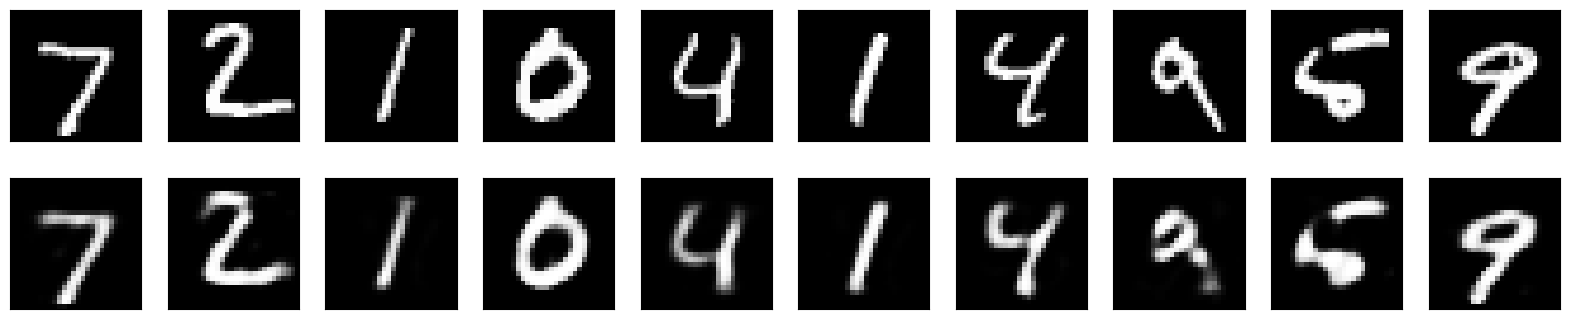

In [10]:

import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruccion
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Limpieza de ruido

In [13]:
# Creamos datos ruidosos
x_test_nois = x_test + 0.2*np.random.randn(x_test.shape[0],x_test.shape[1])
encoded_imgs = encoder.predict(x_test_nois)
decoded_imgs = decoder.predict(encoded_imgs)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


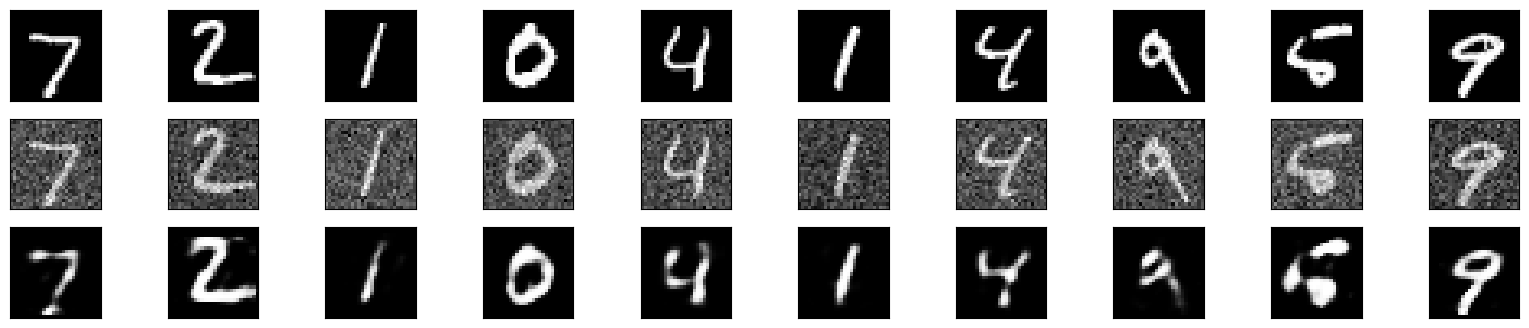

In [14]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Originales
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Ruidosos
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_nois[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstruccion
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Detección de anomalias

## Ejemplo con los datos ruidosos

In [15]:
import numpy as np
# calculamos el error en los datos normales y ruidosos

ncoded_imgs = encoder.predict(x_test_nois)
x_test_nois_pred = decoder.predict(encoded_imgs)

error_nois = np.mean(np.abs(x_test_nois-x_test_nois_pred)**2,tuple(range(1, x_test_nois.ndim)))


x_test_pred = autoencoder.predict(x_test)

error_tes = np.mean(np.abs(x_test-x_test_pred)**2,tuple(range(1, x_test_pred.ndim)))


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


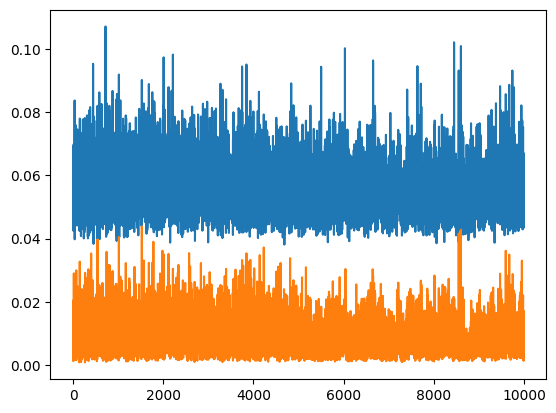

In [16]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_nois)
plt.plot(error_tes)


## Ejemplo inventado

In [76]:
import numpy as np

X_test_anom = x_test.copy()


#Distintos tipos de anomalias

# Zero
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*0

# Max
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*x_test.max()

# Negativo
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))-X_test_anom[1000,:]

# Multiplicado
#X_test_anom[1000,:] = 1.5*X_test_anom[1000,:]

# Ruido
X_test_anom[1000,:] = X_test_anom[1000,:] + 0.5*np.random.randn(1,X_test_anom.shape[1])

# Patch blanco
#X_test_anom[1000,10:14] = 1
#X_test_anom[1000,38:14+28] = 1
#X_test_anom[1000,38+28:14+2*28] = 1
#X_test_anom[1000,38+2*28:14+3*28] = 1



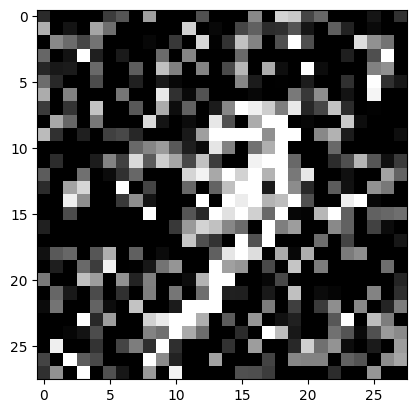

In [77]:
plt.imshow(np.reshape(X_test_anom[1000,:],(28,28)),vmin=0,vmax=1)

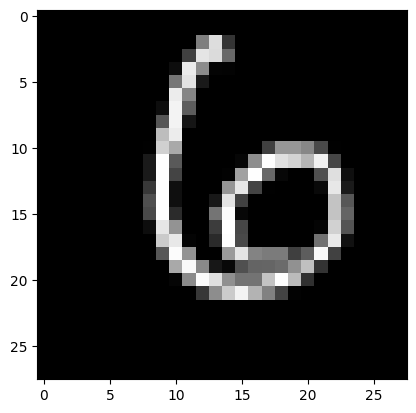

In [78]:
plt.imshow(np.reshape(X_test_anom[100,:],(28,28)))

In [79]:

# calculamos el error en los datos reconstruidos

X_test_anom_pred = autoencoder.predict(X_test_anom)

error_tes = np.mean(np.abs(X_test_anom-X_test_anom_pred)**2,axis = 1)


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


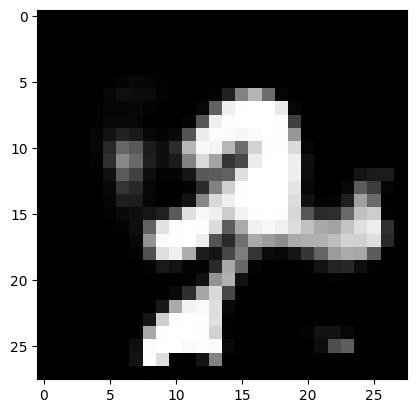

In [80]:
plt.imshow(np.reshape(X_test_anom_pred[1000,:],(28,28)),vmin=0,vmax=1)

In [81]:
error_tes[1000]

0.29246962

In [82]:
error_tes[1]

0.013239625

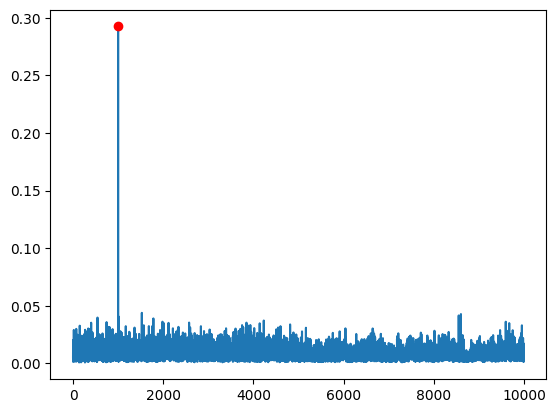

In [83]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_tes)
plt.plot(1000,error_tes[1000],'ro')
